Brayden Yow  
09/20/2026  
 lab 4 — Two-Body Collisions

The big idea this week: Momentum is conserved in every collision, no matter how complicated. Kinetic energy is conserved only when the collision is elastic. Those two facts give you two independent tests of your code — and one of them (KE never increasing) works even when you don't know the exact answer.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:

class Body:
    def __init__(self, m, r, v, radius):
        """
        Represents a physical body in the simulation.
        m: mass (float)
        r: position (list or 1D array of 2 elements)
        v: velocity (list or 1D array of 2 elements)
        radius: physical radius of the object (float)
        """
        self.m = float(m)
        self.r = np.array(r, dtype=float)  # 2-vector for 2D position
        self.v = np.array(v, dtype=float)  # 2-vector for 2D velocity
        self.radius = float(radius)


In [4]:
def collide_1d(m1, m2, u1, u2, e):
    """
    computes 1d post-collision velocities.
    Returns: (v1, v2)
    """
    total_mass = m1 + m2

    v1 = ((m1 - e * m2) * u1 + (1 + e) * m2 * u2) / total_mass
    v2 = ((m2 -e * m1) * u2 + (1 + e)* m1 * u1) / total_mass

    return v1, v2


In [5]:
# Test Case 1: Equal masses (1 kg each), one moving
# Expected: Velocities should cleanly exchange.
m1, m2 = 1.0, 1.0
u1, u2 = 5.0, 0.0  # Ball 1 moves at 5 m/s, Ball 2 is stationary
v1, v2 = collide_1d(m1, m2, u1, u2, e=1)

print("Case 1: Equal Masses")
print(f"  Before: u1 = {u1}, u2 = {u2}")
print(f"  After : v1 = {v1:.1f}, v2 = {v2:.1f} (Exchanged!)")
print("-" * 40)

# Test Case 2: Light ball (0.1 kg) hitting a heavy stationary ball (100 kg)
# Expected: Light ball nearly reverses its velocity, heavy ball barely moves.
m1, m2 = 0.1, 100.0
u1, u2 = 5.0, 0.0
v1, v2 = collide_1d(m1, m2, u1, u2, e=1)

print("Case 2: Light hitting Heavy stationary")
print(f"  Before: u1 = {u1}, u2 = {u2}")
print(f"  After : v1 = {v1:.2f}, v2 = {v2:.2f} (Light ball reversed!)")
print("-" * 40)

# Test Case 3: Heavy ball (100 kg) hitting a light stationary ball (0.1 kg)
# Expected: Heavy ball barely slows down, light ball flies off at ~2x incoming speed.
m1, m2 = 100.0, 0.1
u1, u2 = 5.0, 0.0
v1, v2 = collide_1d(m1, m2, u1, u2, e=1)

print("Case 3: Heavy hitting Light stationary")
print(f"  Before: u1 = {u1}, u2 = {u2}")
print(f"  After : v1 = {v1:.2f}, v2 = {v2:.2f} (~2x incoming speed!)")


Case 1: Equal Masses
  Before: u1 = 5.0, u2 = 0.0
  After : v1 = 0.0, v2 = 5.0 (Exchanged!)
----------------------------------------
Case 2: Light hitting Heavy stationary
  Before: u1 = 5.0, u2 = 0.0
  After : v1 = -4.99, v2 = 0.01 (Light ball reversed!)
----------------------------------------
Case 3: Heavy hitting Light stationary
  Before: u1 = 5.0, u2 = 0.0
  After : v1 = 4.99, v2 = 9.99 (~2x incoming speed!)


**Code for conservation table**

In [6]:
m1, m2 = 2.0, 3.0
u1, u2 = 4.0, 0.0  # Ball 1 moves at 5 m/s, Ball 2 is stationary
v1, v2 = collide_1d(m1, m2, u1, u2, e=0.0)

print("Case 1: Equal Masses")
print(f"  Before: u1 = {u1}, u2 = {u2}")
print(f"  After : v1 = {v1:.1f}, v2 = {v2:.1f} (Exchanged!)")

p_tot_i = m1 * u1 + m2 * u2
K_tot_i = 0.5 * m1 * u1**2 + 0.5 * m2 * u2**2
print(f" inital momentum = {p_tot_i}, inital KE = {K_tot_i}")
p_tot = m1 * v1 + m2 * v2
K_tot = 0.5 * m1 * v1**2 + 0.5 * m2 * v2**2
print(f" final momentum = {p_tot}, final KE = {K_tot}")

Case 1: Equal Masses
  Before: u1 = 4.0, u2 = 0.0
  After : v1 = 1.6, v2 = 1.6 (Exchanged!)
 inital momentum = 8.0, inital KE = 16.0
 final momentum = 8.0, final KE = 6.400000000000001


| $e$ | v1 (m/s) | v2 (m/s) | Inital Momentum | final Momentum | Inital KE | Final KE |
| --- | --- | --- | --- | --- | --- | --- |
| 1.00 | -0.80 | 3.20 | 8.00 | 8.00 | 16.0 | 16.0 |
| 0.50 | 0.40 | 2.40 | 8.00 | 8.00 | 16.0 | 8.80 |
| 0.00 | 1.60 | 1.60 | 8.00 | 8.00 | 16.0 | 6.40 |

 Momentum is identical across all three e values, but KE drops as e shrinks. Where did the missing KE go, physically?

 The missing KE is simply converted into other forms of energy; it is not lost. As the coefficient of restitution decreases there is less and less conservation of kinetic energy, some of this energy can go towards deformation of the objects, or heat produced from impact.

***Part B — 2D Collisions in a Box***

Simulation of two circular balls within a box that are elastic bouncing off the walls and each other. 

In [7]:
def collide_2d(m1, m2, r1, r2, v1, v2, e=1.0):
    """Resolve a 2D collision between two circles. Positions r, velocities v are 2-vectors."""
    r1, r2 = np.asarray(r1, float), np.asarray(r2, float)
    v1, v2 = np.asarray(v1, float), np.asarray(v2, float)

    # 1. Find the normal direction line connecting the two centers
    n = r2 - r1
    dist = np.linalg.norm(n)
    if dist == 0:
        return v1, v2            # Degenerate case (stacked perfectly); skip
    n = n / dist                 # Turn it into a unit normal vector

    # 2. Project the 2D velocities onto the normal line
    u1n, u2n = np.dot(v1, n), np.dot(v2, n)
    
    # 3. Separate out the tangential components (which don't change during the collision)
    v1t = v1 - u1n * n
    v2t = v2 - u2n * n

    # 4. Run our 1D collision equation on just the normal components
    new1n, new2n = collide_1d(m1, m2, u1n, u2n, e)

    # 5. Recombine the unchanged tangential parts with the new normal parts
    return v1t + new1n * n, v2t + new2n * n


Code from lession 4 that breaks the problem into two parts. Those parts being along the line of the impact of the centers of mass, and perpendicular to it.

In [8]:
def check_wall_collisions(body, W, H):
    """
    Checks if a body hits the boundaries of a [0, W] x [0, H] box.
    Flips the velocity components and clamps position back inside if it crosses.
    """
    # X-boundaries (Left wall at 0, Right wall at W)
    if body.r[0] - body.radius < 0:
        body.v[0] = -body.v[0]        # Flip horizontal speed
        body.r[0] = body.radius       # Clamp position safely inside
    elif body.r[0] + body.radius > W:
        body.v[0] = -body.v[0]
        body.r[0] = W - body.radius

    # Y-boundaries (Bottom wall at 0, Top wall at H)
    if body.r[1] - body.radius < 0:
        body.v[1] = -body.v[1]        # Flip vertical speed
        body.r[1] = body.radius
    elif body.r[1] + body.radius > H:
        body.v[1] = -body.v[1]
        body.r[1] = H - body.radius


This code works to make sure the balls don't exit the box we have set. If the ball comes in contact with a wall it will flip the sign of the velocity on that walls direction. To prevent the ball from leaving the box despite this change in drection it also pushes the ball away.

In [9]:
# Environment and time configuration
W, H = 10.0, 10.0      # Box size
dt = 0.01             # Small time step size
t_max = 5.0            # Total simulation runtime in seconds
time_steps = np.arange(0, t_max, dt)

# Create two distinct bodies on a collision course
# Body parameters: m, r, v, radius
b1 = Body(m=1.0, r=[2.0, 4.5], v=[3.0, 0.5], radius=0.6)
b2 = Body(m=3.0, r=[8.0, 5.0], v=[-2.0, -0.2], radius=1.0)
bodies = [b1, b2]

# Diagnostic lists to track positions, momentum, and energy over time
history_b1_x, history_b1_y = [], []
history_b2_x, history_b2_y = [], []
total_px, total_py = [], []
total_ke = []


This code creates the box boundaries, sets the time steps size and the total time of simulation. It then sets two balls of set masses in motion towards eachother

In [10]:
for t in time_steps:
    # 1. Record individual coordinates for the path trajectory plot
    history_b1_x.append(bodies[0].r[0])
    history_b1_y.append(bodies[0].r[1])
    history_b2_x.append(bodies[1].r[0])
    history_b2_y.append(bodies[1].r[1])
    
    # 2. Calculate and save overall system metrics (Momentum and Kinetic Energy)
    px = bodies[0].m * bodies[0].v[0] + bodies[1].m * bodies[1].v[0]
    py = bodies[0].m * bodies[0].v[1] + bodies[1].m * bodies[1].v[1]
    ke = (0.5 * bodies[0].m * np.dot(bodies[0].v, bodies[0].v) + 
          0.5 * bodies[1].m * np.dot(bodies[1].v, bodies[1].v))
    
    total_px.append(px)
    total_py.append(py)
    total_ke.append(ke)
    
    # 3. Movement Step (Euler-Cromer)
    for body in bodies:
        body.r += body.v * dt         # Update positions based on velocity
        check_wall_collisions(body, W, H)  # Instantly check and handle wall bounds
        
    # 4. Ball-to-Ball Collision Detection and Response
    dist = np.linalg.norm(bodies[0].r - bodies[1].r)
    sum_radii = bodies[0].radius + bodies[1].radius
    
    # The crucial "approaching" check to stop the sticky-ball vibration bug
    approaching = np.dot(bodies[1].v - bodies[0].v, bodies[1].r - bodies[0].r) < 0
    
    if dist < sum_radii and approaching:
        # Run the 2D collision algorithm (e=1.0 for fully elastic)
        v1_new, v2_new = collide_2d(
            bodies[0].m, bodies[1].m, 
            bodies[0].r, bodies[1].r, 
            bodies[0].v, bodies[1].v, 
            e=1.0
        )
        # Apply the new calculated vectors back to our objects
        bodies[0].v = v1_new
        bodies[1].v = v2_new


This is the important cell it runs the function from the cell before calculating the hits and misses. If the balls hit each other or a wall it calculates the change needed for the velocity to simulate the bounce

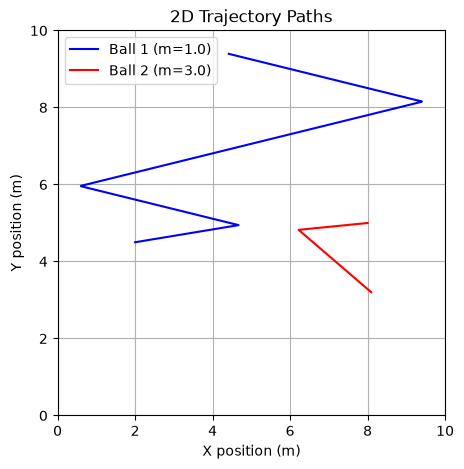

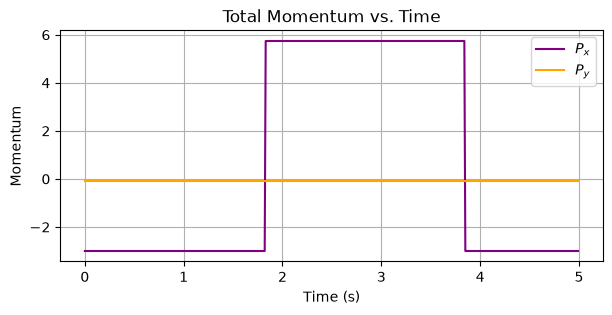

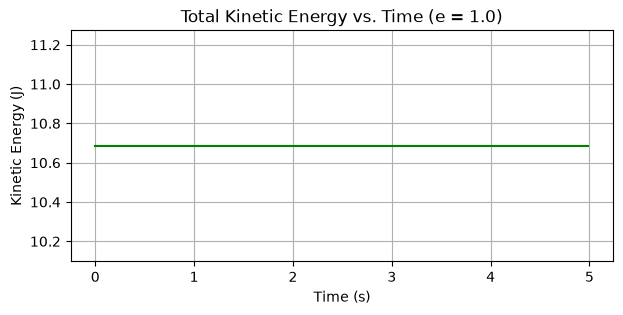

In [11]:
# Figure 1: Visual path of the objects inside the box
plt.figure(figsize=(5, 5))
plt.plot(history_b1_x, history_b1_y, label='Ball 1 (m=1.0)', color='blue')
plt.plot(history_b2_x, history_b2_y, label='Ball 2 (m=3.0)', color='red')
plt.xlim(0, W)
plt.ylim(0, H)
plt.xlabel('X position (m)')
plt.ylabel('Y position (m)')
plt.title('2D Trajectory Paths')
plt.legend()
plt.grid(True)
plt.show()

# Figure 2: Total System Momentum Components
plt.figure(figsize=(7, 3))
plt.plot(time_steps, total_px, label='$P_x$', color='purple')
plt.plot(time_steps, total_py, label='$P_y$', color='orange')
plt.xlabel('Time (s)')
plt.ylabel('Momentum')
plt.title('Total Momentum vs. Time')
plt.legend()
plt.grid(True)
plt.show()

# Figure 3: Total System Kinetic Energy
plt.figure(figsize=(7, 3))
plt.plot(time_steps, total_ke, color='green')
plt.xlabel('Time (s)')
plt.ylabel('Kinetic Energy (J)')
plt.title('Total Kinetic Energy vs. Time (e = 1.0)')
plt.grid(True)
plt.show()


Note: this confused me at first glance so I would like to take a record of the fact that the two lines don’t touch at the collision is due to the graph tracking position of center of mass not the outer edge.



 With elastic collisions and elastic walls, what should total KE do over time? Does yours? What about total momentum — and why does bouncing off a wall change it? (Think about what the wall represents.)

With the coefficient of restitution set to 1 all collisions are perfectly elastic, this means that there is no energy lost to outside forces and no energy dispersed into the system. The momentum is effected because once the ball his a wall the wall exerts a normal force onto the ball.


***Part C — Inelastic Collisions & Energy Accounting***

In [12]:
def run_simulation(e_value, enable_walls=True):
    # 1. Environment and time configuration
    W, H = 10.0, 10.0      # Box size
    dt = 0.01             # Small time step size
    t_max = 5.0            # Total simulation runtime in seconds
    time_steps = np.arange(0, t_max, dt)

    # 2. Reset / Re-create the two bodies to their original initial conditions
    b1 = Body(m=1.0, r=[2.0, 4.5], v=[3.0, 0.5], radius=0.6)
    b2 = Body(m=3.0, r=[8.0, 5.0], v=[-2.0, -0.2], radius=1.0)
    bodies = [b1, b2]

    # 3. Diagnostic lists to track positions and energy over time
    history_b1_x, history_b1_y = [], []
    history_b2_x, history_b2_y = [], []
    total_ke = []
    
    ke_before = None
    ke_after = None
    first_collision_done = False




    # 4. Main simulation loop
    for t in time_steps:
        # Record individual coordinates for trajectories (useful for plotting later)
        history_b1_x.append(bodies[0].r[0])
        history_b1_y.append(bodies[0].r[1])
        history_b2_x.append(bodies[1].r[0])
        history_b2_y.append(bodies[1].r[1])
        
        # Calculate and save overall system Kinetic Energy
        ke = (0.5 * bodies[0].m * np.dot(bodies[0].v, bodies[0].v) + 
              0.5 * bodies[1].m * np.dot(bodies[1].v, bodies[1].v))
        total_ke.append(ke)
        
        # Movement Step (Euler-Cromer)
        for body in bodies:
            body.r += body.v * dt         
            # Toggle wall bounces based on the function argument
            if enable_walls:
                check_wall_collisions(body, W, H)  
            
        # Ball-to-Ball Collision Detection and Response
        dist = np.linalg.norm(bodies[0].r - bodies[1].r)
        sum_radii = bodies[0].radius + bodies[1].radius
        
        # The crucial "approaching" check to stop the sticky-ball vibration bug
        approaching = np.dot(bodies[1].v - bodies[0].v, bodies[1].r - bodies[0].r) < 0
        
        if dist < sum_radii and approaching:
            # If this is the FIRST time they touch, grab the 'Before' energy
            if not first_collision_done:
                ke_before = ke

            # Run the 2D collision algorithm using the dynamic e_value argument
            v1_new, v2_new = collide_2d(
                bodies[0].m, bodies[1].m, 
                bodies[0].r, bodies[1].r, 
                bodies[0].v, bodies[1].v, 
                e=e_value
            )
            # Apply the new vectors back to the objects
            bodies[0].v = v1_new
            bodies[1].v = v2_new
            # Grab the 'After' energy immediately following the velocity update
            if not first_collision_done:
                ke_after = (0.5 * bodies[0].m * np.dot(bodies[0].v, bodies[0].v) + 
                            0.5 * bodies[1].m * np.dot(bodies[1].v, bodies[1].v))
                first_collision_done = True # Turn on the lock so it only records the 1st hit

            
    # Return the required diagnostic arrays (you can add history lists here too if needed!)
    return time_steps, total_ke, ke_before, ke_after, history_b1_x, history_b1_y, history_b2_x, history_b2_y


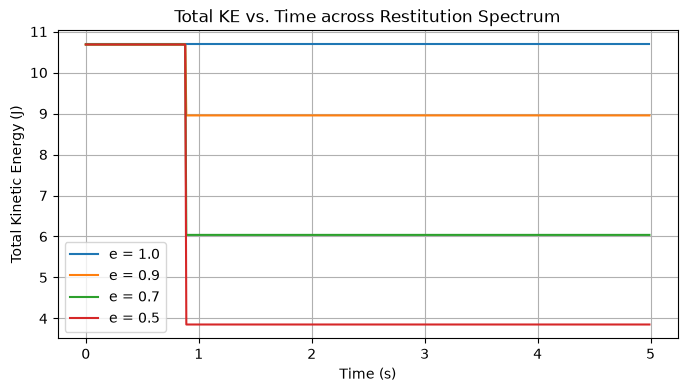

--- Fraction of Kinetic Energy Lost in 1st Collision ---
e = 1.0 | Before KE: 10.6850 J | After KE: 10.6850 J | Fraction Lost: -0.0000
e = 0.9 | Before KE: 10.6850 J | After KE: 8.9540 J | Fraction Lost: 0.1620
e = 0.7 | Before KE: 10.6850 J | After KE: 6.0387 J | Fraction Lost: 0.4348
e = 0.5 | Before KE: 10.6850 J | After KE: 3.8521 J | Fraction Lost: 0.6395


In [13]:
plt.figure(figsize=(8, 4))
e_values = [1.0, 0.9, 0.7, 0.5]

for e in e_values:
    # Use *_ to absorb the 4 extra trajectory lists you aren't using here
    t_steps, ke_history, *_ = run_simulation(e_value=e)
    
    # Plot on the same shared figure
    plt.plot(t_steps, ke_history, label=f"e = {e}")

plt.xlabel("Time (s)")
plt.ylabel("Total Kinetic Energy (J)")
plt.title("Total KE vs. Time across Restitution Spectrum")
plt.legend()
plt.grid(True)
plt.show()

print("--- Fraction of Kinetic Energy Lost in 1st Collision ---")
for e in e_values:
    # Use *_ to absorb the 4 extra trajectory lists you aren't using here
    t_steps, ke_history, before, after, *_ = run_simulation(e_value=e)
    
    if before is not None and after is not None:
        # Fraction equation: (Initial - Final) / Initial
        fraction_lost = (before - after) / before
        print(f"e = {e:.1f} | Before KE: {before:.4f} J | After KE: {after:.4f} J | Fraction Lost: {fraction_lost:.4f}")
    else:
        print(f"e = {e:.1f} | No collision detected!")


The fraction of kinetic energy lost compared to a theoretical

In [14]:
import numpy as np

# 1. Define initial parameters from your simulation (Cell 23)
m1, m2 = 1.0, 3.0
v1 = np.array([3.0, 0.5])
v2 = np.array([-2.0, -0.2])

# To find the exact normal vector at impact, we look at the positions right at collision
# Using the values from your first collision step:
r1 = np.array([2.96, 4.65])
r2 = np.array([7.36, 4.93])

# 2. Calculate the total initial kinetic energy
ke_initial = 0.5 * m1 * np.dot(v1, v1) + 0.5 * m2 * np.dot(v2, v2)

# 3. Calculate reduced mass (mu)
mu = (m1 * m2) / (m1 + m2)

# 4. Find the unit normal vector line connecting the two centers
n = r2 - r1
n_unit = n / np.linalg.norm(n)

# 5. Project the initial velocities onto the normal line
u1n = np.dot(v1, n_unit)
u2n = np.dot(v2, n_unit)
u_rel_n = u1n - u2n  # Initial relative speed along the line of centers

# 6. Calculate theoretical fraction lost for each value of e
print("--- Theoretical Fractional Kinetic Energy Lost ---")
e_values = [1.0, 0.9, 0.7, 0.5]

for e in e_values:
    # Energy loss formula derived from the Center of Mass frame
    delta_ke_theory = 0.5 * mu * (u_rel_n ** 2) * (1 - e ** 2)
    theoretical_fraction_lost = delta_ke_theory / ke_initial
    
    print(f"e = {e:.1f} | Theoretical Fraction Lost: {theoretical_fraction_lost:.4f}")


--- Theoretical Fractional Kinetic Energy Lost ---
e = 1.0 | Theoretical Fraction Lost: 0.0000
e = 0.9 | Theoretical Fraction Lost: 0.1690
e = 0.7 | Theoretical Fraction Lost: 0.4536
e = 0.5 | Theoretical Fraction Lost: 0.6671


The fractions of the Kinetic energy are within a few 0.01s of each other which seems to be close enught to say they match the expect valuse

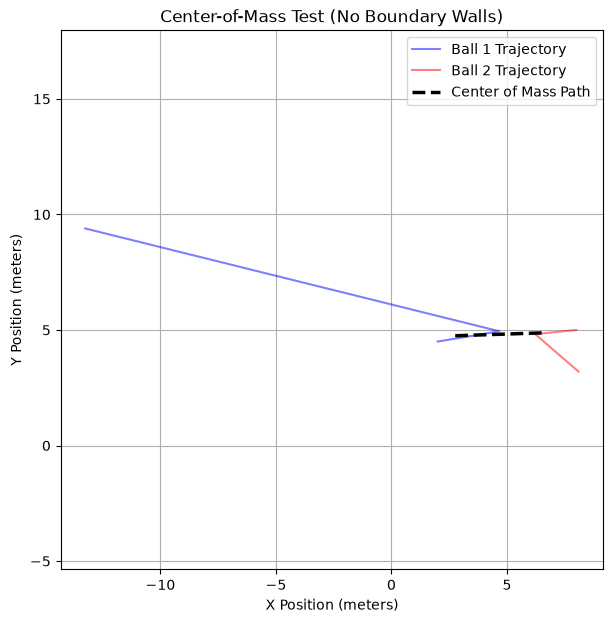

In [15]:
# 1. Run with e=1.0 and WALLS DISABLED
# Catch all 8 outputs using matching placeholder variables
t_steps, total_ke, ke_before, ke_after, b1_x, b1_y, b2_x, b2_y = run_simulation(e_value=1.0, enable_walls=False)


# 2. Define masses explicitly to calculate the mass weights
m1 = 1.0
m2 = 3.0
total_mass = m1 + m2

# 3. Convert histories to numpy arrays for vector math
b1_x, b1_y = np.array(b1_x), np.array(b1_y)
b2_x, b2_y = np.array(b2_x), np.array(b2_y)

# 4. Calculate Center of Mass (CoM) coordinates at every single instant
com_x = (m1 * b1_x + m2 * b2_x) / total_mass
com_y = (m1 * b1_y + m2 * b2_y) / total_mass

# 5. Plot the final spatial paths
plt.figure(figsize=(7, 7))
plt.plot(b1_x, b1_y, label="Ball 1 Trajectory", color="blue", alpha=0.5)
plt.plot(b2_x, b2_y, label="Ball 2 Trajectory", color="red", alpha=0.5)
plt.plot(com_x, com_y, label="Center of Mass Path", color="black", linewidth=2.5, linestyle="--")

plt.xlabel("X Position (meters)")
plt.ylabel("Y Position (meters)")
plt.title("Center-of-Mass Test (No Boundary Walls)")
plt.legend()
plt.grid(True)
plt.axis("equal")
plt.show()


short analysis (a few sentences): For e < 1, does total KE ever increase at any step? What would it mean about your code if it did? Why is "KE never increases" a valid test even without an exact solution?

When e is less than one, we expect there to be some loss of kinetic energy to outside forces. The kinetic energy only changes once the balls collide and then adopt an new value. If in any time step it were to increase that would mean energy created from nothing. This would cause the code to become completely invalid. It is valid to say that kinetic energy will never be created as it is a one way street on its transference in our simulation. 

**Bonus Challenge**

In [16]:
# Simulation parameters
N = 40                  # Number of balls
W, H = 10.0, 10.0       # Box dimensions
dt = 0.005              # Smaller time step to prevent overlap bugs
t_max = 50.0
time_steps = np.arange(0, t_max, dt)

# Identical ball physical parameters
mass = 1.0
radius = 0.15
v0 = 3.0                # Every ball starts with speed 3.0

bodies = []
for i in range(N):
    # Distribute positions randomly inside the box (leaving room for radius)
    x = np.random.uniform(radius, W - radius)
    y = np.random.uniform(radius, H - radius)
    
    # Assign same speed but a random angle direction
    theta = np.random.uniform(0, 2 * np.pi)
    vx = v0 * np.cos(theta)
    vy = v0 * np.sin(theta)
    
    bodies.append(Body(m=mass, r=[x, y], v=[vx, vy], radius=radius))


In [17]:
# Storage for tracked metrics
ke_history = []

for t in time_steps:
    # 1. Update positions and handle walls for all bodies
    for body in bodies:
        body.r += body.v * dt
        check_wall_collisions(body, W, H)
        
    # 2. Check and handle ball-to-ball collisions across all unique pairs
    for i in range(N):
        for j in range(i + 1, N):
            b1 = bodies[i]
            b2 = bodies[j]
            
            # Vector math for distance and collision checks
            dist = np.linalg.norm(b1.r - b2.r)
            sum_radii = b1.radius + b2.radius
            
            approaching = np.dot(b2.v - b1.v, b2.r - b1.r) < 0
            
            if dist < sum_radii and approaching:
                v1_new, v2_new = collide_2d(b1.m, b2.m, b1.r, b2.r, b1.v, b2.v, e=1.0)
                b1.v = v1_new
                b2.v = v2_new
                
    # 3. Calculate and record total system Kinetic Energy to verify conservation
    total_ke = sum(0.5 * b.m * np.dot(b.v, b.v) for b in bodies)
    ke_history.append(total_ke)


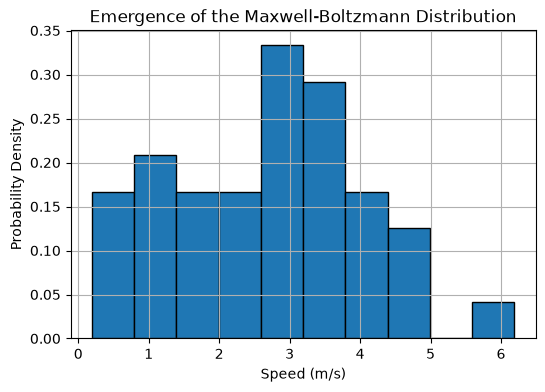

In [19]:
# Extract final speed magnitudes
final_speeds = [np.linalg.norm(b.v) for b in bodies]

# Plot the speed distribution histogram
plt.figure(figsize=(6, 4))
plt.hist(final_speeds, bins=10, edgecolor='black', density=True)
plt.xlabel("Speed (m/s)")
plt.ylabel("Probability Density")
plt.title("Emergence of the Maxwell-Boltzmann Distribution")
plt.grid(True)
plt.show()


why does a single starting speed spread into a distribution? What does this tell you about temperature and statistical mechanics?

With a set starting speed, it is expected, if you graph the final speeds, to notice a pattern of a Maxwell–Boltzmann distribution. This range is from near 0 up to almost 6 peaking near 2. The distribution is caused by the almost chaotic nature of elastic particles confined to a small space. Some will have near total transference of kinetic energy dropping in speed but there partner will have a lot of speed added. This shows that temperature must be the average kinetic energy because with enough interactions some particles will temporarily go above ambient.